# Task 3: Model Research, Validation & Comparison
## Credit Card Fraud Detection

**Objective:** Build and compare three machine learning models on the dataset prepared in Task 2, validate and tune them fairly, report suitable results, and save the selected model together with its preprocessing.

**Workflow:** Research → Pipeline → Default Baselines → Validation → Tuning → Comparison → Save

| # | Section | # | Section |
|---|---|---|---|
| 01 | Setup and Imports | 09 | Hyperparameter Tuning |
| 02 | Data Loading and Task 2 Feature Engineering | 10 | Tuned Model Evaluation |
| 03 | Feature Groups and Class Imbalance | 11 | Model Comparison and Winner Selection |
| 04 | Research and Selection of Three Models | 12 | Decision Threshold Selection |
| 05 | Preprocessing and Pipeline Construction | 13 | Final Training and Test Evaluation |
| 06 | Development Sample and Validation Strategy | 14 | Feature Importance |
| 07 | Default Model Baselines | 15 | Saving, Reloading, and Inference |
| 08 | Cross-Validation Results and Generalization | 16 | Conclusion and Submission Checklist |

### How Task 1 and Task 2 Are Reused

| Source | Reused in Task 3 |
|---|---|
| Task 1 (EDA) | Same raw files and target `is_fraud`; strong class imbalance, so accuracy alone is not enough; `amt` outliers are kept. |
| Task 2 (Preprocessing) | Same `create_features()`, same dropped columns, same 17 input features, same preprocessing definition, same original train / test split. |

**One deliberate change:** the fitted Task 2 preprocessor is **not** loaded. The same preprocessing *definition* is rebuilt inside each model `Pipeline`, so it is re-fitted inside every cross-validation fold (leakage rule).

**Test-set rule:** `fraudTest.csv` is not used for any decision. It is evaluated **once**, in Section 13. The save / reload demonstrations in Section 15 use **training** rows only.

## 01 Setup and Imports

### 1.1 Import Libraries

Import the libraries for data handling, preprocessing, models, validation, metrics, plotting and model saving.

In [1]:
import os
import json
import time
import warnings
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import sklearn
import lightgbm

from scipy.stats import loguniform

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV, train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    classification_report, roc_curve, precision_recall_curve,
    ConfusionMatrixDisplay,
)

### 1.2 Global Configuration

- `RANDOM_STATE = 42` fixes every random step (sampling, folds, searches, models) for reproducible results.
- Outputs are written to `task3_output_improved/`.

In [2]:
warnings.filterwarnings("ignore", category=UserWarning)

RANDOM_STATE = 42
OUTPUT_DIR = "task3_output_improved"
os.makedirs(OUTPUT_DIR, exist_ok=True)

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

print("Python      :", platform.python_version())
print("pandas      :", pd.__version__)
print("scikit-learn:", sklearn.__version__)
print("lightgbm    :", lightgbm.__version__)

Python      : 3.13.18
pandas      : 3.0.5
scikit-learn: 1.9.1
lightgbm    : 4.7.0


### 1.3 Plot Style

Each model keeps one fixed colour in every chart, so the plots are easy to compare.

In [3]:
MODEL_COLORS = {
    "Logistic Regression": "#2a78d6",   # blue
    "Random Forest": "#eb6834",         # orange
    "LightGBM": "#1baf7a",              # green
}
DEFAULT_GREY = "#b8b7b2"

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e6e6e3",
    "grid.linewidth": 0.8,
    "axes.edgecolor": "#8a8984",
    "axes.labelcolor": "#2b2b2a",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "lines.linewidth": 2,
})

## 02 Data Loading and Task 2 Feature Engineering

### 2.1 Load the Raw Data

Load the same training and testing files used in Task 1 and Task 2.

In [4]:
df_train = pd.read_csv("archive/fraudTrain.csv")
df_test = pd.read_csv("archive/fraudTest.csv")

print("Raw Train Shape:", df_train.shape)
print("Raw Test Shape :", df_test.shape)

Raw Train Shape: (1296675, 23)
Raw Test Shape : (555719, 23)


### 2.2 Task 2 Feature Engineering Function

The function is copied **unchanged** from Task 2. It creates four features without using the target:

| Feature | Meaning |
|---|---|
| `trans_hour` | Hour of the transaction (0–23) |
| `trans_day` | Day of the week (Monday = 0) |
| `customer_age` | Customer age on the transaction date |
| `distance_km` | Haversine distance between customer and merchant |

In [5]:
def create_features(df):
    """Task 2 feature engineering (unchanged): time, age and distance features."""
    df = df.copy()

    # Convert dates
    df["trans_date_trans_time"] = pd.to_datetime(df["trans_date_trans_time"])
    df["dob"] = pd.to_datetime(df["dob"])

    # Transaction time features
    df["trans_hour"] = df["trans_date_trans_time"].dt.hour
    df["trans_day"] = df["trans_date_trans_time"].dt.dayofweek

    # Customer age at transaction time
    df["customer_age"] = (
        df["trans_date_trans_time"].dt.year
        - df["dob"].dt.year
        - (
            (df["trans_date_trans_time"].dt.month * 100
             + df["trans_date_trans_time"].dt.day)
            < (df["dob"].dt.month * 100 + df["dob"].dt.day)
        )
    )

    # Haversine distance between customer and merchant (km)
    lat1, lon1 = np.radians(df["lat"]), np.radians(df["long"])
    lat2, lon2 = np.radians(df["merch_lat"]), np.radians(df["merch_long"])
    a = (np.sin((lat2 - lat1) / 2) ** 2
         + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2)
    a = np.clip(a, 0, 1)
    df["distance_km"] = 6371 * 2 * np.arcsin(np.sqrt(a))

    return df

### 2.3 Remove Unnecessary Columns

Identifiers, personal information and redundant time columns are dropped, exactly as in Task 2. `prepare_features()` combines feature creation and column removal; it is reused later for **inference** on new raw transactions.

In [6]:
DROP_COLUMNS = [
    "Unnamed: 0", "cc_num", "trans_num", "first", "last",
    "street", "trans_date_trans_time", "dob", "unix_time",
]
TARGET = "is_fraud"


def prepare_features(df_raw):
    """Raw transactions -> the 17 Task 2 input features (+ target if present)."""
    df = create_features(df_raw).drop(columns=DROP_COLUMNS)
    for col in ["trans_hour", "trans_day", "customer_age", "distance_km"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")   # Task 2, step 3.4
    return df

### 2.4 Define Input Features (X) and Target (y)

Apply the same preparation to both files and separate the features from the target. The original train / test split is preserved.

In [7]:
train_df = prepare_features(df_train)
test_df = prepare_features(df_test)

X_train = train_df.drop(columns=[TARGET])
y_train = train_df[TARGET]
X_test = test_df.drop(columns=[TARGET])
y_test = test_df[TARGET]

print("X_train:", X_train.shape, "| y_train:", y_train.shape)
print("X_test :", X_test.shape, "| y_test :", y_test.shape)
print("Same feature columns:", X_train.columns.equals(X_test.columns))

X_train: (1296675, 17) | y_train: (1296675,)
X_test : (555719, 17) | y_test : (555719,)
Same feature columns: True


**Result:** both datasets have the same **17 input features**, and the test set (555,719 rows) is set aside for the final evaluation only.

## 03 Feature Groups and Class Imbalance

### 3.1 Identify Numerical and Categorical Features

Feature groups are identified as in Task 2 (step 3.4). They decide which preprocessing each column receives.

In [8]:
numerical_features = X_train.select_dtypes(include="number").columns.tolist()
categorical_features = X_train.select_dtypes(exclude="number").columns.tolist()

print(f"Numerical features ({len(numerical_features)}):", numerical_features)
print(f"Categorical features ({len(categorical_features)}):", categorical_features)

Numerical features (11): ['amt', 'zip', 'lat', 'long', 'city_pop', 'merch_lat', 'merch_long', 'trans_hour', 'trans_day', 'customer_age', 'distance_km']
Categorical features (6): ['merchant', 'category', 'gender', 'city', 'state', 'job']


### 3.2 Check the Class Distribution

Analyse the target on the training data only.

In [9]:
balance = pd.DataFrame({
    "Count": y_train.value_counts().sort_index(),
    "Percent": (y_train.value_counts(normalize=True).sort_index() * 100).round(3),
})
balance.index = ["Legitimate (0)", "Fraud (1)"]
display(balance)

majority_accuracy = 1 - y_train.mean()
print(f"Accuracy of always predicting 'legitimate': {majority_accuracy:.4%}")

,Count,Percent
Legitimate (0),1289169,99.421
Fraud (1),7506,0.579


Accuracy of always predicting 'legitimate': 99.4211%


**Interpretation:** fraud is only about **0.58 %** of transactions (about 1 in 172). A model that never predicts fraud already reaches about **99.4 % accuracy**, so accuracy cannot be the main metric.

## 04 Research and Selection of Three Models

### 4.1 Identify the Task

| Item | Decision |
|---|---|
| Learning problem | Supervised **binary classification** (`is_fraud`: 0 = legitimate, 1 = fraud) |
| Main difficulty | Severe class imbalance (≈ 0.58 % fraud) |
| Goal | Rank fraud above legitimate transactions and catch most frauds with few false alarms |
| **Main metric** | **Average Precision (PR-AUC)** of the fraud class |
| Supporting metrics | Precision, Recall, F1 (fraud class), ROC-AUC, Accuracy, Confusion Matrix |

**Why Average Precision?** It summarises the whole precision–recall curve, does not depend on one threshold, and is not inflated by the very large number of true negatives (unlike accuracy and, to a lesser degree, ROC-AUC).

### 4.2 Three Suitable Algorithms

Three models from **different families** were selected so that the comparison is informative:

- **Logistic Regression (linear model):** a weighted sum of the features passed through the sigmoid function. It is a fast, interpretable baseline that works directly on the sparse one-hot matrix, with `class_weight` for imbalance. It can only learn a linear boundary.
- **Random Forest (bagging):** many decision trees trained on bootstrap samples with random feature subsets; their probabilities are averaged. It learns non-linear patterns and interactions and is robust to outliers and scaling, but it is slow on large data and gives large model files.
- **LightGBM (gradient boosting):** shallow trees built sequentially, each correcting the errors of the previous ones, with histogram-based, leaf-wise growth and native sparse support. It is state of the art for tabular data and has imbalance and regularisation controls, but it has many hyperparameters.

### 4.3 Research Summary Table

In [10]:
research_summary = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Family": "Linear model",
        "Reason for choosing": "Fast, interpretable baseline; handles the sparse one-hot matrix; class_weight for imbalance",
        "Strengths": "Simple, fast, calibrated probabilities, coefficients are interpretable",
        "Limitations": "Linear decision boundary; cannot learn feature interactions by itself",
        "Key hyperparameters": "C, penalty, class_weight, solver, max_iter",
        "Reference": "https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression",
    },
    {
        "Model": "Random Forest",
        "Family": "Bagging ensemble of trees",
        "Reason for choosing": "Captures non-linear patterns and interactions; robust to outliers and scaling",
        "Strengths": "Low variance, little tuning needed, feature importances",
        "Limitations": "Slow on large data, large model files, probabilities less calibrated",
        "Key hyperparameters": "n_estimators, max_depth, min_samples_leaf, max_features, class_weight",
        "Reference": "https://scikit-learn.org/stable/modules/ensemble.html#random-forests ; Breiman (2001), Machine Learning 45:5-32",
    },
    {
        "Model": "LightGBM",
        "Family": "Gradient-boosted trees",
        "Reason for choosing": "State of the art on tabular data; fast; native sparse input; imbalance controls",
        "Strengths": "High accuracy, fast training, regularisation options, feature importances",
        "Limitations": "Many hyperparameters; can over-fit or become unstable if poorly tuned",
        "Key hyperparameters": "n_estimators, learning_rate, num_leaves, min_child_samples, subsample, colsample_bytree, reg_lambda, scale_pos_weight",
        "Reference": "https://lightgbm.readthedocs.io/en/latest/Parameters.html ; Ke et al. (2017), NeurIPS",
    },
])

research_summary.to_csv(f"{OUTPUT_DIR}/research_summary.csv", index=False)
display(research_summary.style.hide(axis="index")
        .set_properties(**{"text-align": "left", "white-space": "pre-wrap"}))

Model,Family,Reason for choosing,Strengths,Limitations,Key hyperparameters,Reference
Logistic Regression,Linear model,"Fast, interpretable baseline; handles the sparse one-hot matrix; class_weight for imbalance","Simple, fast, calibrated probabilities, coefficients are interpretable",Linear decision boundary; cannot learn feature interactions by itself,"C, penalty, class_weight, solver, max_iter",https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
Random Forest,Bagging ensemble of trees,Captures non-linear patterns and interactions; robust to outliers and scaling,"Low variance, little tuning needed, feature importances","Slow on large data, large model files, probabilities less calibrated","n_estimators, max_depth, min_samples_leaf, max_features, class_weight","https://scikit-learn.org/stable/modules/ensemble.html#random-forests ; Breiman (2001), Machine Learning 45:5-32"
LightGBM,Gradient-boosted trees,State of the art on tabular data; fast; native sparse input; imbalance controls,"High accuracy, fast training, regularisation options, feature importances",Many hyperparameters; can over-fit or become unstable if poorly tuned,"n_estimators, learning_rate, num_leaves, min_child_samples, subsample, colsample_bytree, reg_lambda, scale_pos_weight","https://lightgbm.readthedocs.io/en/latest/Parameters.html ; Ke et al. (2017), NeurIPS"


## 05 Preprocessing and Pipeline Construction

### 5.1 Build the Task 2 Preprocessor

The definition is identical to Task 2:

- **Numerical:** median imputation → `StandardScaler`.
- **Categorical:** most-frequent imputation → `OneHotEncoder(handle_unknown="ignore", sparse_output=True)`.

`handle_unknown="ignore"` prevents errors when a new merchant or city appears in a validation fold or in the test set.

In [11]:
def build_preprocessor():
    """Exact Task 2 preprocessing definition (unfitted)."""
    numerical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=True)),
    ])
    return ColumnTransformer([
        ("num", numerical_pipeline, numerical_features),
        ("cat", categorical_pipeline, categorical_features),
    ])

### 5.2 Combine Preprocessing and Model in One Pipeline

**Leakage rule:** because the preprocessor is a step of the pipeline, `fit()` learns medians, scaling statistics and one-hot categories **only from the training folds** of each split. Nothing is pre-processed on the whole dataset beforehand.

In [12]:
def build_pipeline(estimator):
    """Preprocessing + estimator in a single, leakage-safe pipeline."""
    return Pipeline([
        ("preprocessor", build_preprocessor()),
        ("model", estimator),
    ])

### 5.3 Create the Three Default Pipelines

Default hyperparameters are used. Only essential settings are changed:

| Setting | Reason |
|---|---|
| `random_state=42` | Reproducibility |
| `max_iter=1000` (Logistic Regression) | Lets the `lbfgs` solver converge on ~2,000 features |
| `n_jobs=-1` | Uses all CPU cores (speed only) |
| `verbose=-1` (LightGBM) | Silences training logs |

In [13]:
default_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    "LightGBM": LGBMClassifier(random_state=RANDOM_STATE, n_jobs=-1, verbose=-1),
}

default_pipelines = {name: build_pipeline(est) for name, est in default_models.items()}
default_pipelines["LightGBM"]

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the

## 06 Development Sample and Validation Strategy

### 6.1 Create the Development Sample

Running 5-fold CV and randomized searches for three models on all 1,296,675 training rows would need several hundred full fits. Therefore:

1. Development (baselines, CV, tuning) uses a **stratified sample of 250,000 training rows**.
2. The selected pipeline is **re-fitted on all training rows** in Section 13.
3. The test set is never used for development decisions.

In [14]:
DEV_SIZE = 250_000

X_dev, _, y_dev, _ = train_test_split(
    X_train, y_train,
    train_size=DEV_SIZE,
    stratify=y_train,
    random_state=RANDOM_STATE,
)
X_dev = X_dev.reset_index(drop=True)
y_dev = y_dev.reset_index(drop=True)

print("Development sample:", X_dev.shape)
print(f"Fraud rate - full train: {y_train.mean():.4%} | dev sample: {y_dev.mean():.4%}")
print("Fraud cases in dev sample:", int(y_dev.sum()))

Development sample: (250000, 17)
Fraud rate - full train: 0.5789% | dev sample: 0.5788%
Fraud cases in dev sample: 1447


**Interpretation:** stratification keeps the fraud rate unchanged (0.5788 % vs 0.5789 %), so the sample represents the full training data.

### 6.2 Cross-Validation Strategy

`StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`:

- Each fold keeps the same fraud rate (about 290 fraud cases per validation fold).
- The **same fold object** is used for every model, for the baselines and for tuning, so all results are directly comparable.
- Results are reported as **mean ± standard deviation** across the 5 folds.

In [15]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
MAIN_METRIC = "avg_precision"

### 6.3 Metric Helper

Average Precision and ROC-AUC use the predicted **probabilities** (threshold-independent). Precision, Recall, F1 and Accuracy use the **predicted labels** at a threshold (0.5 during model comparison).

In [16]:
def compute_metrics(y_true, y_proba, threshold=0.5):
    """All classification metrics used in this notebook (fraud = positive class)."""
    y_pred = (y_proba >= threshold).astype(int)
    return {
        "avg_precision": average_precision_score(y_true, y_proba),
        "roc_auc": roc_auc_score(y_true, y_proba),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "accuracy": accuracy_score(y_true, y_pred),
    }

### 6.4 Cross-Validation Helper

For each fold, `evaluate_cv()`:

1. clones the pipeline, so preprocessing and model are re-fitted from scratch on the training folds;
2. records the training time;
3. computes metrics on the training folds and on the validation fold (to detect over- or under-fitting);
4. stores the **out-of-fold (OOF)** probabilities: one validation prediction for every development row.

In [17]:
def evaluate_cv(name, pipeline, X, y, cv):
    """Manual stratified K-fold CV with per-fold refitting of the whole pipeline."""
    fold_rows = []
    oof_proba = np.zeros(len(y))

    for fold, (tr_idx, va_idx) in enumerate(cv.split(X, y), start=1):
        model = clone(pipeline)

        start = time.perf_counter()
        model.fit(X.iloc[tr_idx], y.iloc[tr_idx])
        fit_time = time.perf_counter() - start

        train_proba = model.predict_proba(X.iloc[tr_idx])[:, 1]
        val_proba = model.predict_proba(X.iloc[va_idx])[:, 1]
        oof_proba[va_idx] = val_proba

        row = {"model": name, "fold": fold, "fit_time_s": fit_time}
        row.update({f"train_{k}": v for k, v in compute_metrics(y.iloc[tr_idx], train_proba).items()})
        row.update({f"val_{k}": v for k, v in compute_metrics(y.iloc[va_idx], val_proba).items()})
        fold_rows.append(row)

    folds = pd.DataFrame(fold_rows)
    print(f"{name:<20} val {MAIN_METRIC} = {folds['val_' + MAIN_METRIC].mean():.4f} "
          f"± {folds['val_' + MAIN_METRIC].std():.4f} | mean fit time {folds['fit_time_s'].mean():.1f}s")
    return {"folds": folds, "oof_proba": oof_proba}

### 6.5 Summary Helper

Turns the fold results into one table with **mean ± std** for each validation metric.

In [18]:
METRIC_NAMES = ("avg_precision", "roc_auc", "f1", "precision", "recall", "accuracy")


def summarize(results, metrics=METRIC_NAMES):
    """Mean ± std across folds for each model."""
    rows = []
    for name, res in results.items():
        f = res["folds"]
        row = {"Model": name}
        for m in metrics:
            row[f"val_{m}"] = f"{f['val_' + m].mean():.4f} ± {f['val_' + m].std():.4f}"
        row["train_avg_precision"] = f"{f['train_avg_precision'].mean():.4f}"
        row["fit_time_s"] = round(f["fit_time_s"].mean(), 2)
        rows.append(row)
    return pd.DataFrame(rows).set_index("Model")

## 07 Default Model Baselines

### 7.1 Train the Default Models with Cross-Validation

Each default pipeline is evaluated with the same 5 stratified folds (15 fits in total).

In [19]:
baseline_results = {}
for name, pipe in default_pipelines.items():
    baseline_results[name] = evaluate_cv(name, pipe, X_dev, y_dev, cv)

Logistic Regression  val avg_precision = 0.2243 ± 0.0269 | mean fit time 1.0s


Random Forest        val avg_precision = 0.7921 ± 0.0266 | mean fit time 17.1s


LightGBM             val avg_precision = 0.6483 ± 0.1955 | mean fit time 1.6s


### 7.2 Record the Baseline Settings

Only the parameters that are tuned later are shown. LightGBM lists `scale_pos_weight` in `get_params()` only once it is set explicitly, so its documented default (1.0) is filled in.

In [20]:
key_params = {
    "Logistic Regression": ["C", "class_weight", "solver", "max_iter"],
    "Random Forest": ["n_estimators", "max_depth", "min_samples_leaf", "max_features", "class_weight"],
    "LightGBM": ["n_estimators", "learning_rate", "num_leaves", "min_child_samples",
                 "subsample", "colsample_bytree", "reg_lambda", "scale_pos_weight"],
}
LIBRARY_DEFAULTS = {"scale_pos_weight": 1.0}


def get_settings(estimator, names):
    params = estimator.get_params()
    return {p: params.get(p, LIBRARY_DEFAULTS.get(p)) for p in names}


def fmt_params(params):
    return ", ".join(f"{k}={round(v, 4) if isinstance(v, float) else v}" for k, v in params.items())


baseline_settings = {name: get_settings(default_models[name], key_params[name]) for name in default_models}
display(pd.DataFrame({"Default settings": {n: fmt_params(p) for n, p in baseline_settings.items()}})
        .style.set_properties(**{"text-align": "left"}))

,Default settings
Logistic Regression,"C=1.0, class_weight=None, solver=lbfgs, max_iter=1000"
Random Forest,"n_estimators=100, max_depth=None, min_samples_leaf=1, max_features=sqrt, class_weight=None"
LightGBM,"n_estimators=100, learning_rate=0.1, num_leaves=31, min_child_samples=20, subsample=1.0, colsample_bytree=1.0, reg_lambda=0.0, scale_pos_weight=1.0"


### 7.3 Keep the Baseline Predictions

The out-of-fold probabilities of the default models are kept for later comparison.

In [21]:
baseline_oof = pd.DataFrame({name: res["oof_proba"] for name, res in baseline_results.items()})
baseline_oof["is_fraud"] = y_dev.values
baseline_oof.head()

,Logistic Regression,Random Forest,LightGBM,is_fraud
0,0.000002,0.0,0.000004,0
1,0.003205,0.0,0.025440,0
2,0.003699,0.0,0.000038,0
3,0.002395,0.0,0.000038,0
4,0.001763,0.0,0.000021,0


## 08 Cross-Validation Results and Generalization

### 8.1 Default Model Results (mean ± std over 5 folds)

In [22]:
baseline_summary = summarize(baseline_results)
baseline_summary.to_csv(f"{OUTPUT_DIR}/baseline_cv_summary.csv")
display(baseline_summary)

,val_avg_precision,val_roc_auc,val_f1,val_precision,val_recall,val_accuracy,train_avg_precision,fit_time_s
Model,,,,,,,,
Logistic Regression,0.2243 ± 0.0269,0.8284 ± 0.0145,0.0799 ± 0.0276,0.3718 ± 0.0699,0.0449 ± 0.0163,0.9941 ± 0.0001,0.3318,0.99
Random Forest,0.7921 ± 0.0266,0.9528 ± 0.0096,0.6663 ± 0.0237,0.9877 ± 0.0058,0.5031 ± 0.0265,0.9971 ± 0.0002,1.0000,17.07
LightGBM,0.6483 ± 0.1955,0.9602 ± 0.0392,0.7223 ± 0.0879,0.7427 ± 0.1467,0.7104 ± 0.0453,0.9968 ± 0.0013,0.8466,1.59


### 8.2 Validation Average Precision per Fold

The spread across folds shows how **stable** each model is.

In [23]:
baseline_folds = pd.concat([r["folds"] for r in baseline_results.values()], ignore_index=True)
baseline_folds.to_csv(f"{OUTPUT_DIR}/baseline_cv_folds.csv", index=False)

fold_table = baseline_folds.pivot(index="fold", columns="model", values="val_avg_precision")
display(fold_table[list(default_models)].round(4))

model,Logistic Regression,Random Forest,LightGBM
fold,,,
1,0.2028,0.7664,0.8407
2,0.2321,0.8157,0.5113
3,0.2158,0.7963,0.7067
4,0.2032,0.7628,0.3826
5,0.2674,0.8192,0.8002


### 8.3 Training vs. Validation Gap

A low score on both sets suggests **under-fitting**; a large gap suggests **over-fitting**; a large fold standard deviation suggests **unstable** performance.

In [24]:
def generalization_table(results):
    """Train vs validation Average Precision for each model."""
    return pd.DataFrame({
        name: {
            "train_AP": r["folds"]["train_avg_precision"].mean(),
            "val_AP": r["folds"]["val_avg_precision"].mean(),
            "gap (train - val)": r["folds"]["train_avg_precision"].mean() - r["folds"]["val_avg_precision"].mean(),
            "val_AP std": r["folds"]["val_avg_precision"].std(),
        } for name, r in results.items()
    }).T.round(4)


display(generalization_table(baseline_results))

,train_AP,val_AP,gap (train - val),val_AP std
Logistic Regression,0.3318,0.2243,0.1075,0.0269
Random Forest,1.0000,0.7921,0.2079,0.0266
LightGBM,0.8466,0.6483,0.1983,0.1955


### 8.4 Visualise the Generalization Check

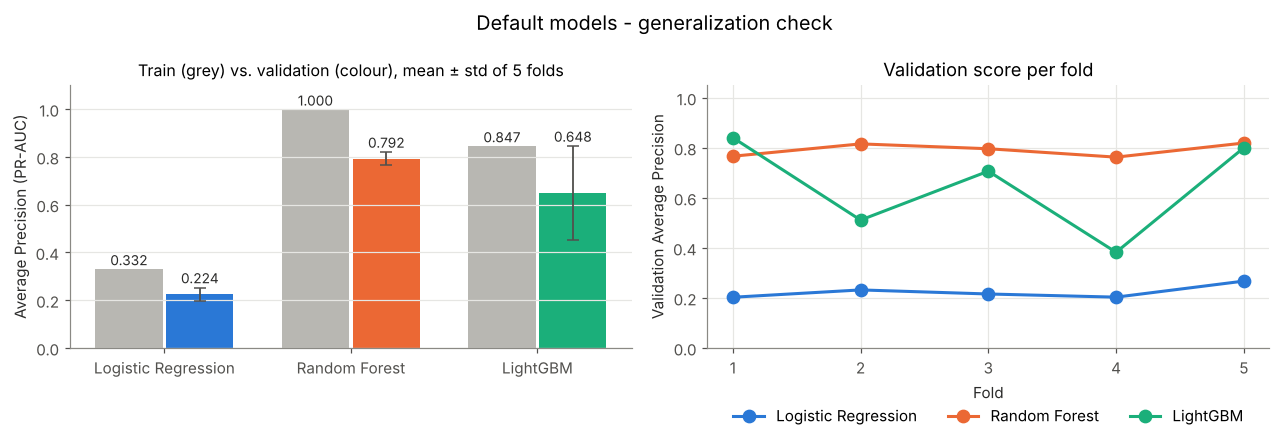

In [25]:
def plot_train_vs_val(results, title):
    names = list(results)
    x = np.arange(len(names))
    width = 0.36
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

    # Left: mean train vs validation main metric
    train_means = [results[n]["folds"]["train_avg_precision"].mean() for n in names]
    val_means = [results[n]["folds"]["val_avg_precision"].mean() for n in names]
    val_stds = [results[n]["folds"]["val_avg_precision"].std() for n in names]
    axes[0].bar(x - width / 2 - 0.01, train_means, width, color=DEFAULT_GREY)
    axes[0].bar(x + width / 2 + 0.01, val_means, width, yerr=val_stds, capsize=4,
                color=[MODEL_COLORS[n] for n in names], error_kw={"ecolor": "#52514e", "elinewidth": 1.2})
    for i, (t, v, sd) in enumerate(zip(train_means, val_means, val_stds)):
        axes[0].text(i - width / 2 - 0.01, t + 0.015, f"{t:.3f}", ha="center", fontsize=9, color="#2b2b2a")
        axes[0].text(i + width / 2 + 0.01, v + sd + 0.02, f"{v:.3f}", ha="center", fontsize=9, color="#2b2b2a")
    axes[0].set_xticks(x, names)
    axes[0].set_ylim(0, 1.1)
    axes[0].set_ylabel("Average Precision (PR-AUC)")
    axes[0].set_title("Train (grey) vs. validation (colour), mean ± std of 5 folds", fontsize=10.5)
    axes[0].grid(axis="x", visible=False)

    # Right: per-fold validation scores (stability)
    for n in names:
        f = results[n]["folds"]
        axes[1].plot(f["fold"], f["val_avg_precision"], marker="o", markersize=8,
                     color=MODEL_COLORS[n], label=n)
    axes[1].set_xticks(range(1, 6))
    axes[1].set_xlabel("Fold")
    axes[1].set_ylabel("Validation Average Precision")
    axes[1].set_ylim(0, 1.05)
    axes[1].set_title("Validation score per fold")
    axes[1].legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=3)

    fig.suptitle(title, fontsize=13)
    fig.tight_layout()
    plt.show()


plot_train_vs_val(baseline_results, "Default models - generalization check")

### 8.5 Interpretation of the Default Baselines

| Model | Diagnosis | Evidence |
|---|---|---|
| Logistic Regression | **Under-fitting** | Low train AP (≈ 0.33) and val AP (≈ 0.22); recall at 0.5 is below 5 %. A linear boundary cannot capture fraud patterns. |
| Random Forest | Strong but **over-fitting** | Train AP = 1.00 vs val AP ≈ 0.79, yet stable across folds (± 0.03). Very precise (≈ 0.99) but catches only about half of the frauds. |
| LightGBM | **Unstable** | Mean val AP ≈ 0.65 with a very large spread (± 0.20; folds from ≈ 0.38 to ≈ 0.84); even the train AP drops on some folds. With the default learning rate and ≈ 1,150 frauds per training fold, boosting is unstable on this imbalanced data. |

These default results are the fixed reference for the tuning step. Before tuning, **Random Forest** is the strongest model.

## 09 Hyperparameter Tuning

### 9.1 Search Spaces

Tuning starts only after the baselines were recorded. A small, sensible space is searched for each model:

| Model | Tuned parameters | Why |
|---|---|---|
| Logistic Regression | `C` (1e-3 – 1e2, log scale), `class_weight` | Regularisation strength on ~2,000 sparse columns; re-weighting the rare fraud class |
| Random Forest | `n_estimators`, `max_depth`, `min_samples_leaf`, `max_features`, `class_weight` | Number / depth of trees control variance and over-fitting; feature sampling controls diversity |
| LightGBM | `n_estimators`, `learning_rate`, `num_leaves`, `min_child_samples`, `subsample`, `colsample_bytree`, `reg_lambda`, `scale_pos_weight` | Boosting budget, tree complexity, row / column sampling, L2 regularisation, fraud class weight |

`loguniform` samples `C` and `learning_rate` evenly across orders of magnitude, because their effect is multiplicative.

In [26]:
search_spaces = {
    "Logistic Regression": {
        "model__C": loguniform(1e-3, 1e2),
        "model__class_weight": [None, "balanced"],
    },
    "Random Forest": {
        "model__n_estimators": [100, 200, 300],
        "model__max_depth": [None, 20, 30],
        "model__min_samples_leaf": [1, 2, 4],
        "model__max_features": ["sqrt", 0.03],
        "model__class_weight": [None, "balanced_subsample"],
    },
    "LightGBM": {
        "model__n_estimators": [200, 400, 800],
        "model__learning_rate": loguniform(0.01, 0.2),
        "model__num_leaves": [15, 31, 63, 127],
        "model__min_child_samples": [10, 20, 50, 100],
        "model__subsample": [0.7, 0.85, 1.0],
        "model__subsample_freq": [1],
        "model__colsample_bytree": [0.3, 0.5, 0.8, 1.0],
        "model__reg_lambda": [0.0, 1.0, 5.0, 10.0],
        "model__scale_pos_weight": [1, 3, 10, 30],
    },
}

# Number of sampled candidates (bounded by the cost of one fit)
n_iter = {"Logistic Regression": 12, "Random Forest": 8, "LightGBM": 15}

### 9.2 Run the Randomized Searches

`RandomizedSearchCV` settings:

| Argument | Purpose |
|---|---|
| `estimator=pipe` | The whole pipeline, so preprocessing is refitted inside every fold |
| `scoring="average_precision"`, `cv=cv` | Same main metric and same 5 folds as the baselines |
| `refit=False` | The final refit happens later on the full training set |
| `n_jobs=1` | The models themselves already use all cores |
| `error_score="raise"` | Any failing fit stops the search instead of being hidden |

In [27]:
searches = {}
search_times = {}

for name, pipe in default_pipelines.items():
    search = RandomizedSearchCV(
        estimator=pipe,
        param_distributions=search_spaces[name],
        n_iter=n_iter[name],
        scoring="average_precision",
        cv=cv,                     # same folds as the baselines
        refit=False,               # final refit happens later on the full training set
        random_state=RANDOM_STATE,
        n_jobs=1,                  # models themselves use all cores
        error_score="raise",
    )
    start = time.perf_counter()
    search.fit(X_dev, y_dev)
    search_times[name] = time.perf_counter() - start
    searches[name] = search
    print(f"{name:<20} best CV AP = {search.best_score_:.4f} "
          f"(search time {search_times[name] / 60:.1f} min)")

Logistic Regression  best CV AP = 0.2380 (search time 1.6 min)


Random Forest        best CV AP = 0.8087 (search time 14.1 min)


LightGBM             best CV AP = 0.8882 (search time 7.3 min)


### 9.3 Best Hyperparameters

In [28]:
best_params_table = pd.DataFrame({
    name: {
        "Best CV AP": round(search.best_score_, 4),
        "Best parameters": fmt_params({k.replace("model__", ""): v for k, v in search.best_params_.items()}),
        "Search time (min)": round(search_times[name] / 60, 1),
    } for name, search in searches.items()
}).T
display(best_params_table.style.set_properties(**{"text-align": "left"}))

,Best CV AP,Best parameters,Search time (min)
Logistic Regression,0.238000,"C=0.1695, class_weight=None",1.600000
Random Forest,0.808700,"n_estimators=200, min_samples_leaf=1, max_features=0.03, max_depth=None, class_weight=None",14.100000
LightGBM,0.888200,"colsample_bytree=0.8, learning_rate=0.0331, min_child_samples=100, n_estimators=800, num_leaves=31, reg_lambda=1.0, scale_pos_weight=10, subsample=0.85, subsample_freq=1",7.300000


### 9.4 Top 5 Candidates of Each Search

All search results are saved to CSV. Note: `std_test_score` from scikit-learn uses the population standard deviation (`ddof=0`), while the summaries in this notebook use pandas `.std()` (`ddof=1`), so the standard deviations differ slightly.

In [29]:
for name, search in searches.items():
    res = pd.DataFrame(search.cv_results_)
    res.to_csv(f"{OUTPUT_DIR}/search_results_{name.replace(' ', '_').lower()}.csv", index=False)

    cols = [c for c in res.columns if c.startswith("param_")] + ["mean_test_score", "std_test_score"]
    top = res.sort_values("rank_test_score")[cols].head(5).copy()
    for c in cols:
        if c.startswith("param_"):   # show None explicitly instead of NaN
            top[c] = top[c].apply(lambda v: "None" if v is None or (isinstance(v, float) and np.isnan(v)) else v)
    top.columns = [c.replace("param_model__", "") for c in top.columns]

    print(f"\n{name} - top 5 of {len(res)} candidates")
    display(top.round(4))


Logistic Regression - top 5 of 12 candidates


,C,class_weight,mean_test_score,std_test_score
3,0.1695,None,0.2380,0.0221
0,0.0746,None,0.2338,0.0240
11,1.1436,None,0.2283,0.0249
2,0.9847,None,0.2244,0.0205
9,0.0010,balanced,0.1997,0.0172



Random Forest - top 5 of 8 candidates


,n_estimators,min_samples_leaf,max_features,max_depth,class_weight,mean_test_score,std_test_score
1,200,1,0.03,None,None,0.8087,0.0228
5,200,2,0.03,None,balanced_subsample,0.7810,0.0284
2,200,2,sqrt,None,None,0.7735,0.0268
4,300,4,sqrt,None,balanced_subsample,0.7287,0.0334
7,100,1,0.03,30,None,0.7166,0.0327



LightGBM - top 5 of 15 candidates


,colsample_bytree,learning_rate,min_child_samples,n_estimators,num_leaves,reg_lambda,scale_pos_weight,subsample,subsample_freq,mean_test_score,std_test_score
4,0.8,0.0331,100,800,31,1.0,10,0.85,1,0.8882,0.0122
14,0.8,0.0181,100,800,63,0.0,10,0.70,1,0.8835,0.0122
5,0.8,0.0314,100,200,63,0.0,10,1.00,1,0.8810,0.0166
11,0.8,0.0476,20,200,127,0.0,3,1.00,1,0.8798,0.0139
1,0.5,0.0160,50,800,127,0.0,30,1.00,1,0.8792,0.0147


**Interpretation:** for LightGBM, all of the top 4 candidates use `colsample_bytree=0.8`, and the top 3 use `scale_pos_weight=10`. For Logistic Regression, `class_weight="balanced"` lowered Average Precision. For Random Forest, the best candidate used more trees with `max_features=0.03`.

## 10 Tuned Model Evaluation

### 10.1 Re-evaluate the Tuned Pipelines

The best configuration of each search is evaluated again with `evaluate_cv()` on the **same five folds**, so default and tuned models are compared with exactly the same criteria (train / validation metrics, timing and OOF predictions).

In [30]:
tuned_pipelines = {
    name: clone(default_pipelines[name]).set_params(**searches[name].best_params_)
    for name in default_pipelines
}

tuned_results = {}
for name, pipe in tuned_pipelines.items():
    tuned_results[name] = evaluate_cv(name, pipe, X_dev, y_dev, cv)

tuned_settings = {
    name: get_settings(tuned_pipelines[name].named_steps["model"], key_params[name])
    for name in tuned_pipelines
}

Logistic Regression  val avg_precision = 0.2380 ± 0.0248 | mean fit time 0.8s


Random Forest        val avg_precision = 0.8087 ± 0.0255 | mean fit time 33.0s


LightGBM             val avg_precision = 0.8882 ± 0.0137 | mean fit time 6.4s


### 10.2 Tuned Model Results (mean ± std over 5 folds)

In [31]:
tuned_summary = summarize(tuned_results)
tuned_summary.to_csv(f"{OUTPUT_DIR}/tuned_cv_summary.csv")
display(tuned_summary)
display(generalization_table(tuned_results))

,val_avg_precision,val_roc_auc,val_f1,val_precision,val_recall,val_accuracy,train_avg_precision,fit_time_s
Model,,,,,,,,
Logistic Regression,0.2380 ± 0.0248,0.8235 ± 0.0129,0.0167 ± 0.0098,0.1203 ± 0.0741,0.0090 ± 0.0053,0.9939 ± 0.0001,0.2802,0.81
Random Forest,0.8087 ± 0.0255,0.9610 ± 0.0080,0.6965 ± 0.0311,0.9911 ± 0.0034,0.5377 ± 0.0373,0.9973 ± 0.0002,1.0000,32.97
LightGBM,0.8882 ± 0.0137,0.9946 ± 0.0021,0.8375 ± 0.0113,0.8811 ± 0.0180,0.7989 ± 0.0268,0.9982 ± 0.0001,1.0000,6.39


,train_AP,val_AP,gap (train - val),val_AP std
Logistic Regression,0.2802,0.2380,0.0422,0.0248
Random Forest,1.0000,0.8087,0.1913,0.0255
LightGBM,1.0000,0.8882,0.1118,0.0137


### 10.3 Default vs. Tuned Comparison

In [32]:
compare_rows = []
for name in default_pipelines:
    for version, res in [("Default", baseline_results[name]), ("Tuned", tuned_results[name])]:
        f = res["folds"]
        compare_rows.append({
            "Model": name, "Version": version,
            "val_AP_mean": f["val_avg_precision"].mean(), "val_AP_std": f["val_avg_precision"].std(),
            "val_ROC_AUC": f["val_roc_auc"].mean(), "val_F1": f["val_f1"].mean(),
            "val_Precision": f["val_precision"].mean(), "val_Recall": f["val_recall"].mean(),
            "train_AP": f["train_avg_precision"].mean(), "fit_time_s": f["fit_time_s"].mean(),
        })
default_vs_tuned = pd.DataFrame(compare_rows)
default_vs_tuned.to_csv(f"{OUTPUT_DIR}/default_vs_tuned.csv", index=False)
display(default_vs_tuned.set_index(["Model", "Version"]).round(4))

val_AP_mean  val_AP_std  val_ROC_AUC  val_F1  val_Precision  val_Recall  train_AP  fit_time_s
Model               Version                                                                                               
Logistic Regression Default       0.2243      0.0269       0.8284  0.0799         0.3718      0.0449    0.3318      0.9896
                    Tuned         0.2380      0.0248       0.8235  0.0167         0.1203      0.0090    0.2802      0.8100
Random Forest       Default       0.7921      0.0266       0.9528  0.6663         0.9877      0.5031    1.0000     17.0739
                    Tuned         0.8087      0.0255       0.9610  0.6965         0.9911      0.5377    1.0000     32.9685
LightGBM            Default       0.6483      0.1955       0.9602  0.7223         0.7427      0.7104    0.8466      1.5892
                    Tuned         0.8882      0.0137       0.9946  0.8375         0.8811      0.7989    1.0000      6.3861

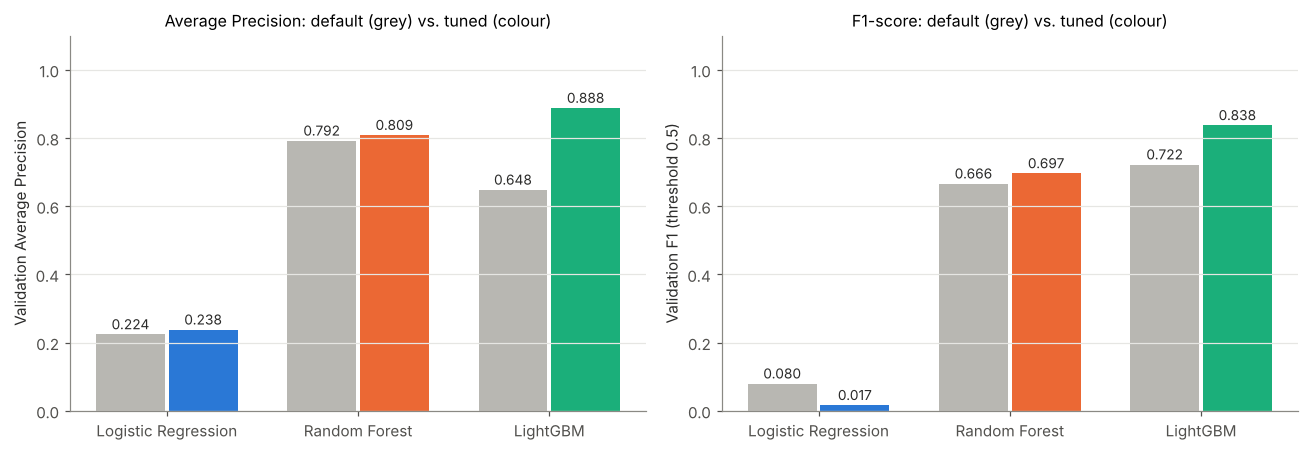

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
names = list(default_pipelines)
x = np.arange(len(names))
width = 0.36
for ax, metric, label in [(axes[0], "val_AP_mean", "Validation Average Precision"),
                          (axes[1], "val_F1", "Validation F1 (threshold 0.5)")]:
    d = default_vs_tuned[default_vs_tuned["Version"] == "Default"].set_index("Model").loc[names, metric]
    t = default_vs_tuned[default_vs_tuned["Version"] == "Tuned"].set_index("Model").loc[names, metric]
    ax.bar(x - width / 2 - 0.01, d, width, color=DEFAULT_GREY)
    ax.bar(x + width / 2 + 0.01, t, width, color=[MODEL_COLORS[n] for n in names])
    for i in range(len(names)):
        ax.text(i - width / 2 - 0.01, d.iloc[i] + 0.015, f"{d.iloc[i]:.3f}", ha="center", fontsize=9, color="#2b2b2a")
        ax.text(i + width / 2 + 0.01, t.iloc[i] + 0.015, f"{t.iloc[i]:.3f}", ha="center", fontsize=9, color="#2b2b2a")
    ax.set_xticks(x, names)
    ax.set_ylim(0, 1.1)
    ax.set_ylabel(label)
    ax.grid(axis="x", visible=False)
axes[0].set_title("Average Precision: default (grey) vs. tuned (colour)", fontsize=10.5)
axes[1].set_title("F1-score: default (grey) vs. tuned (colour)", fontsize=10.5)
fig.tight_layout()
plt.show()

**Interpretation:**

- **LightGBM benefits most:** Average Precision rises from **0.648 ± 0.196** to **0.888 ± 0.014**. The fold variation drops more than tenfold. A smaller learning rate (≈ 0.033) with 800 trees, `min_child_samples=100`, row / column subsampling, L2 regularisation and `scale_pos_weight=10` stabilise the boosting.
- **Random Forest improves slightly:** 0.792 → 0.809. Train AP stays at 1.0 and the fit time roughly doubles.
- **Logistic Regression stays weak:** 0.224 → 0.238. The limit is the linear model family, not its hyperparameters. Its F1 at 0.5 even drops (0.080 → 0.017) because the search optimised Average Precision (ranking), not F1 at a fixed threshold.

### 10.4 Out-of-Fold Metrics of the Tuned Models

These metrics use the pooled out-of-fold predictions of all 250,000 development rows (threshold 0.5). They are computed once on all OOF predictions, so they can differ slightly from the fold means above.

In [34]:
oof_metrics = pd.DataFrame({
    name: compute_metrics(y_dev, res["oof_proba"]) for name, res in tuned_results.items()
}).T
oof_metrics.columns = ["Avg Precision", "ROC-AUC", "F1", "Precision", "Recall", "Accuracy"]
display(oof_metrics.round(4))

,Avg Precision,ROC-AUC,F1,Precision,Recall,Accuracy
Logistic Regression,0.2361,0.8234,0.0167,0.1140,0.0090,0.9939
Random Forest,0.8085,0.9610,0.6971,0.9911,0.5377,0.9973
LightGBM,0.8882,0.9946,0.8377,0.8804,0.7989,0.9982


### 10.5 Confusion Matrices (out-of-fold, threshold 0.5)

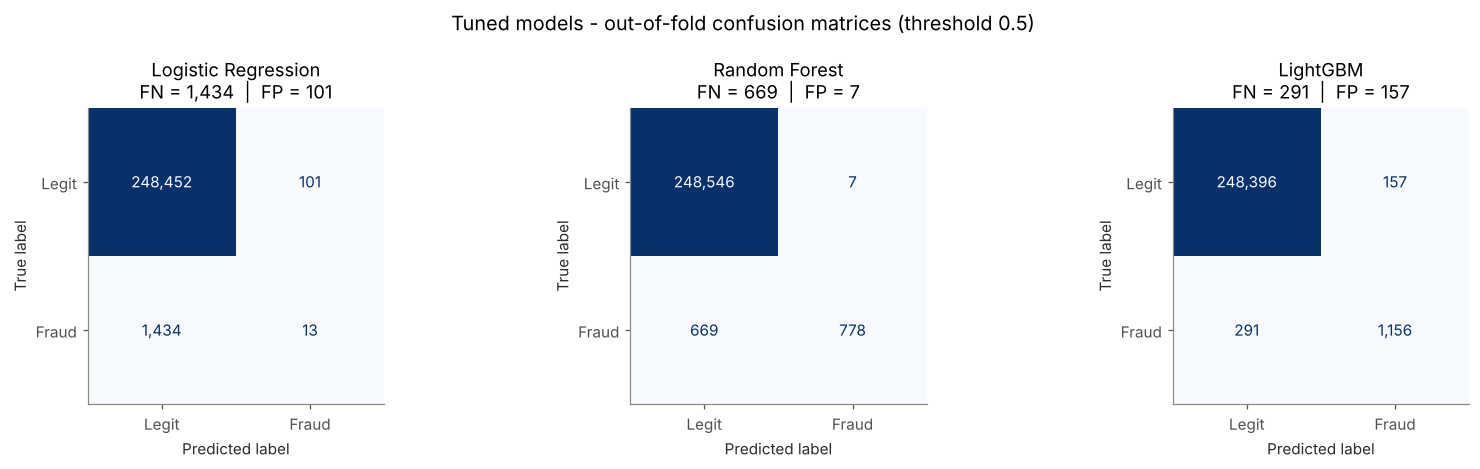

In [35]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
for ax, (name, res) in zip(axes, tuned_results.items()):
    cm = confusion_matrix(y_dev, (res["oof_proba"] >= 0.5).astype(int))
    ConfusionMatrixDisplay(cm, display_labels=["Legit", "Fraud"]).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format=",")
    ax.set_title(f"{name}\nFN = {cm[1, 0]:,}  |  FP = {cm[0, 1]:,}")
    ax.grid(False)
fig.suptitle("Tuned models - out-of-fold confusion matrices (threshold 0.5)", fontsize=13)
fig.tight_layout()
plt.show()

### 10.6 ROC and Precision–Recall Curves

On imbalanced data the ROC curve can look very good because the false-positive *rate* is divided by a huge number of negatives. The Precision–Recall curve is more informative; the dashed line is the no-skill level (the fraud rate).

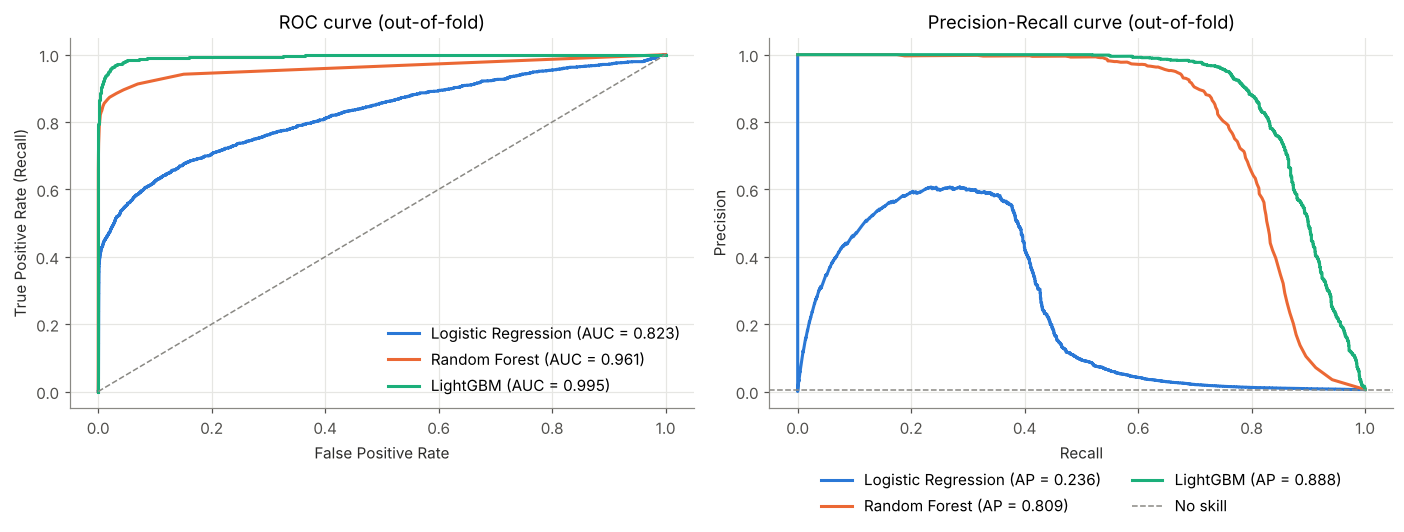

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, res in tuned_results.items():
    fpr, tpr, _ = roc_curve(y_dev, res["oof_proba"])
    prec, rec, _ = precision_recall_curve(y_dev, res["oof_proba"])
    axes[0].plot(fpr, tpr, color=MODEL_COLORS[name],
                 label=f"{name} (AUC = {roc_auc_score(y_dev, res['oof_proba']):.3f})")
    axes[1].plot(rec, prec, color=MODEL_COLORS[name],
                 label=f"{name} (AP = {average_precision_score(y_dev, res['oof_proba']):.3f})")

axes[0].plot([0, 1], [0, 1], linestyle="--", color="#8a8984", linewidth=1)
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate (Recall)")
axes[0].set_title("ROC curve (out-of-fold)")
axes[0].legend(frameon=False, loc="lower right")

axes[1].axhline(y_dev.mean(), linestyle="--", color="#8a8984", linewidth=1, label="No skill")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall curve (out-of-fold)")
axes[1].legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=2)
fig.tight_layout()
plt.show()

**Interpretation:**

- **Accuracy is misleading:** all models exceed 99.3 %, even Logistic Regression, which catches only 13 of 1,447 frauds.
- **PR vs. ROC:** Logistic Regression reaches ROC-AUC ≈ 0.82 but AP ≈ 0.24. The PR curve separates the models much more clearly.
- **Error trade-off:** Random Forest has very few false positives (7) but misses about half of the frauds (669). Tuned LightGBM finds about 80 % of frauds with ≈ 88 % precision: the best balance.

## 11 Model Comparison and Winner Selection

### 11.1 Final Comparison Table

One table with default and tuned settings, the main validation metric, supporting metrics and training time for each model.

In [37]:
comparison_rows = []
for name in default_pipelines:
    b, t = baseline_results[name]["folds"], tuned_results[name]["folds"]
    comparison_rows.append({
        "Model": name,
        "Default settings": fmt_params(baseline_settings[name]),
        "Tuned settings": fmt_params(tuned_settings[name]),
        "Default val AP (mean ± std)": f"{b['val_avg_precision'].mean():.4f} ± {b['val_avg_precision'].std():.4f}",
        "Tuned val AP (mean ± std)": f"{t['val_avg_precision'].mean():.4f} ± {t['val_avg_precision'].std():.4f}",
        "Tuned val ROC-AUC": round(t["val_roc_auc"].mean(), 4),
        "Tuned val F1": round(t["val_f1"].mean(), 4),
        "Tuned val Precision": round(t["val_precision"].mean(), 4),
        "Tuned val Recall": round(t["val_recall"].mean(), 4),
        "Tuned train AP": round(t["train_avg_precision"].mean(), 4),
        "Default fit time (s)": round(b["fit_time_s"].mean(), 2),
        "Tuned fit time (s)": round(t["fit_time_s"].mean(), 2),
        "Search time (min)": round(search_times[name] / 60, 1),
    })
comparison_table = pd.DataFrame(comparison_rows).set_index("Model")
comparison_table.to_csv(f"{OUTPUT_DIR}/model_comparison.csv")
display(comparison_table.T.style.set_properties(**{"text-align": "left", "white-space": "pre-wrap"}))

Model,Logistic Regression,Random Forest,LightGBM
Default settings,"C=1.0, class_weight=None, solver=lbfgs, max_iter=1000","n_estimators=100, max_depth=None, min_samples_leaf=1, max_features=sqrt, class_weight=None","n_estimators=100, learning_rate=0.1, num_leaves=31, min_child_samples=20, subsample=1.0, colsample_bytree=1.0, reg_lambda=0.0, scale_pos_weight=1.0"
Tuned settings,"C=0.1695, class_weight=None, solver=lbfgs, max_iter=1000","n_estimators=200, max_depth=None, min_samples_leaf=1, max_features=0.03, class_weight=None","n_estimators=800, learning_rate=0.0331, num_leaves=31, min_child_samples=100, subsample=0.85, colsample_bytree=0.8, reg_lambda=1.0, scale_pos_weight=10"
Default val AP (mean ± std),0.2243 ± 0.0269,0.7921 ± 0.0266,0.6483 ± 0.1955
Tuned val AP (mean ± std),0.2380 ± 0.0248,0.8087 ± 0.0255,0.8882 ± 0.0137
Tuned val ROC-AUC,0.823500,0.961000,0.994600
Tuned val F1,0.016700,0.696500,0.837500
Tuned val Precision,0.120300,0.991100,0.881100
Tuned val Recall,0.009000,0.537700,0.798900
Tuned train AP,0.280200,1.000000,1.000000
Default fit time (s),0.990000,17.070000,1.590000


### 11.2 Rank the Tuned Models by Cross-Validation

The winner is the tuned model with the **highest mean validation Average Precision**. Stability (fold std) and the train–validation gap are checked as well. The test set is **not** used for this decision.

In [38]:
selection = pd.DataFrame({
    name: {
        "val_AP_mean": r["folds"]["val_avg_precision"].mean(),
        "val_AP_std": r["folds"]["val_avg_precision"].std(),
        "train_val_gap": r["folds"]["train_avg_precision"].mean() - r["folds"]["val_avg_precision"].mean(),
        "val_F1_mean": r["folds"]["val_f1"].mean(),
        "fit_time_s": r["folds"]["fit_time_s"].mean(),
    } for name, r in tuned_results.items()
}).T.sort_values("val_AP_mean", ascending=False)
display(selection.round(4))

best_model_name = selection.index[0]
runner_up = selection.index[1]
margin = selection.loc[best_model_name, "val_AP_mean"] - selection.loc[runner_up, "val_AP_mean"]
print(f"Selected model: {best_model_name}")
print(f"Margin over runner-up ({runner_up}): {margin:.4f} AP "
      f"(= {margin / selection.loc[runner_up, 'val_AP_std']:.1f} x runner-up fold std)")

,val_AP_mean,val_AP_std,train_val_gap,val_F1_mean,fit_time_s
LightGBM,0.8882,0.0137,0.1118,0.8375,6.3861
Random Forest,0.8087,0.0255,0.1913,0.6965,32.9685
Logistic Regression,0.2380,0.0248,0.0422,0.0167,0.8100


Selected model: LightGBM
Margin over runner-up (Random Forest): 0.0795 AP (= 3.1 x runner-up fold std)


### 11.3 Why LightGBM Was Selected

| Criterion | Evidence (tuned models, 5-fold CV) |
|---|---|
| **Best generalisation** | Highest validation AP (**0.888**), ROC-AUC (0.995) and F1 (0.84). The margin over Random Forest (≈ 0.08 AP) is about **3× Random Forest's fold std**, so it is not fold noise. |
| **Most stable** | Lowest fold standard deviation (± 0.014). |
| **Less over-fitting than Random Forest** | Both reach train AP 1.0, but LightGBM's train–validation gap is smaller (≈ 0.11 vs ≈ 0.19). |
| **Performance vs. complexity** | About 5× faster than tuned Random Forest (≈ 7.5 s vs ≈ 38 s per fold) with a much smaller model file. Logistic Regression is simpler and faster, but far too weak on fraud. |

**Selected model: tuned LightGBM.** The decision is based only on cross-validation on training data.

## 12 Decision Threshold Selection

### 12.1 Find the Threshold with the Best F1 (training data only)

The default threshold of 0.5 is not necessarily best for an imbalanced problem. The threshold is chosen on the **out-of-fold predictions of LightGBM** (training data only) as the value that maximises the fraud-class F1-score. It is fixed **before** the test set is evaluated.

In [39]:
best_oof = tuned_results[best_model_name]["oof_proba"]
prec, rec, thr = precision_recall_curve(y_dev, best_oof)
f1_values = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
best_idx = int(np.nanargmax(f1_values))
DECISION_THRESHOLD = float(thr[best_idx])

print(f"Selected decision threshold: {DECISION_THRESHOLD:.4f}")

Selected decision threshold: 0.7397


### 12.2 Compare the Default and Selected Thresholds

In [40]:
threshold_table = pd.DataFrame({
    "Threshold 0.5": compute_metrics(y_dev, best_oof, 0.5),
    f"Threshold {DECISION_THRESHOLD:.3f} (max F1)": compute_metrics(y_dev, best_oof, DECISION_THRESHOLD),
}).T
display(threshold_table.round(4))

,avg_precision,roc_auc,f1,precision,recall,accuracy
Threshold 0.5,0.8882,0.9946,0.8377,0.8804,0.7989,0.9982
Threshold 0.740 (max F1),0.8882,0.9946,0.8445,0.9499,0.7602,0.9984


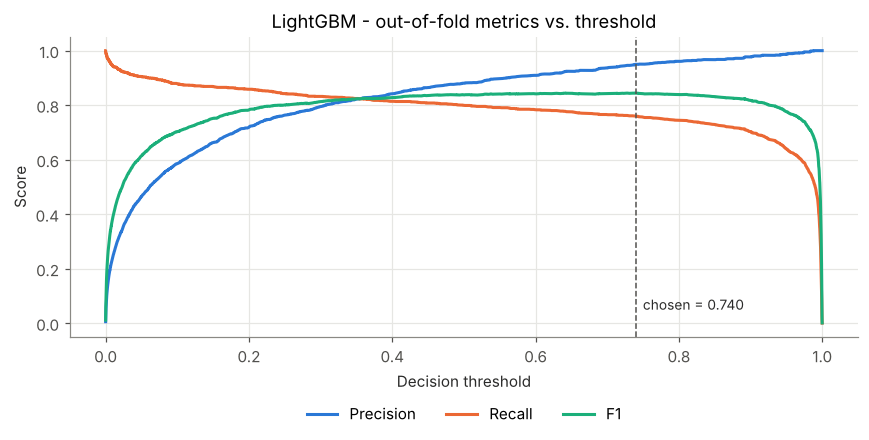

In [41]:
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(thr, prec[:-1], color="#2a78d6", label="Precision")
ax.plot(thr, rec[:-1], color="#eb6834", label="Recall")
ax.plot(thr, f1_values, color="#1baf7a", label="F1")
ax.axvline(DECISION_THRESHOLD, color="#52514e", linestyle="--", linewidth=1)
ax.text(DECISION_THRESHOLD + 0.01, 0.05, f"chosen = {DECISION_THRESHOLD:.3f}", color="#2b2b2a", fontsize=9)
ax.set_xlabel("Decision threshold")
ax.set_ylabel("Score")
ax.set_title(f"{best_model_name} - out-of-fold metrics vs. threshold")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3)
fig.tight_layout()
plt.show()

**Interpretation:** raising the threshold to ≈ 0.74 increases precision from 0.88 to 0.95 while recall decreases slightly from 0.80 to 0.76, so F1 improves (0.8377 → 0.8445). Average Precision and ROC-AUC do not change because they do not depend on the threshold.

## 13 Final Training and Test Evaluation

### 13.1 Re-fit the Selected Pipeline on All Training Data

The tuned LightGBM pipeline (preprocessing + model) is re-fitted on all **1,296,675** training rows. The preprocessing is again learned from training data only.

In [42]:
final_pipeline = clone(tuned_pipelines[best_model_name])

start = time.perf_counter()
final_pipeline.fit(X_train, y_train)
final_fit_time = time.perf_counter() - start

n_processed = final_pipeline.named_steps["preprocessor"].get_feature_names_out().shape[0]
print(f"Final model: {best_model_name}")
print(f"Trained on {X_train.shape[0]:,} rows, {X_train.shape[1]} input features "
      f"-> {n_processed:,} processed features")
print(f"Final fit time: {final_fit_time / 60:.2f} min")

Final model: LightGBM
Trained on 1,296,675 rows, 17 input features -> 2,159 processed features
Final fit time: 0.52 min


### 13.2 Predict the Untouched Test Set (once)

This is the **first and only** use of the test set. All 555,719 test rows are scored.

In [43]:
start = time.perf_counter()
test_proba = final_pipeline.predict_proba(X_test)[:, 1]
predict_time = time.perf_counter() - start
test_pred = (test_proba >= DECISION_THRESHOLD).astype(int)

print(f"Prediction time for {len(X_test):,} test rows: {predict_time:.1f}s")

Prediction time for 555,719 test rows: 7.2s


### 13.3 Final Test Metrics

The selected threshold is the official result. The 0.5 row is shown for reference only (no decision is based on it). The CV row shows the development estimate for comparison.

In [44]:
test_metrics = compute_metrics(y_test, test_proba, DECISION_THRESHOLD)
test_metrics_05 = compute_metrics(y_test, test_proba, 0.5)

final_results = pd.DataFrame({
    f"Test (threshold {DECISION_THRESHOLD:.3f})": test_metrics,
    "Test (threshold 0.5, reference)": test_metrics_05,
    "CV validation (dev, mean)": {
        k: tuned_results[best_model_name]["folds"][f"val_{k}"].mean() for k in test_metrics
    },
}).T
display(final_results.round(4))

,avg_precision,roc_auc,f1,precision,recall,accuracy
Test (threshold 0.740),0.8444,0.9962,0.7978,0.8356,0.7632,0.9985
"Test (threshold 0.5, reference)",0.8444,0.9962,0.7222,0.6511,0.8107,0.9976
"CV validation (dev, mean)",0.8882,0.9946,0.8375,0.8811,0.7989,0.9982


In [45]:
print(classification_report(y_test, test_pred, target_names=["Legitimate", "Fraud"], digits=4))

              precision    recall  f1-score   support

  Legitimate     0.9991    0.9994    0.9993    553574
       Fraud     0.8356    0.7632    0.7978      2145

    accuracy                         0.9985    555719
   macro avg     0.9174    0.8813    0.8985    555719
weighted avg     0.9985    0.9985    0.9985    555719



### 13.4 Test Confusion Matrix, ROC and Precision–Recall Curves

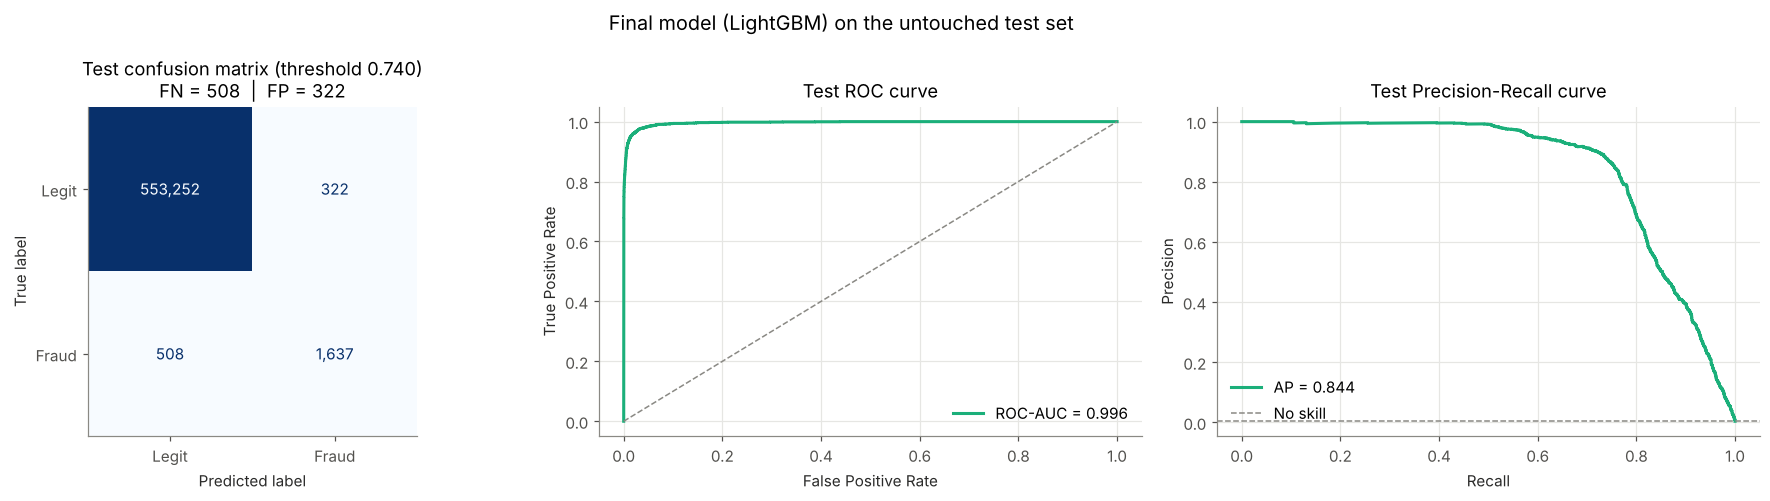

In [46]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))

cm = confusion_matrix(y_test, test_pred)
ConfusionMatrixDisplay(cm, display_labels=["Legit", "Fraud"]).plot(
    ax=axes[0], cmap="Blues", colorbar=False, values_format=",")
axes[0].set_title(f"Test confusion matrix (threshold {DECISION_THRESHOLD:.3f})\n"
                  f"FN = {cm[1, 0]:,}  |  FP = {cm[0, 1]:,}")
axes[0].grid(False)

color = MODEL_COLORS[best_model_name]
fpr, tpr, _ = roc_curve(y_test, test_proba)
axes[1].plot(fpr, tpr, color=color, label=f"ROC-AUC = {test_metrics['roc_auc']:.3f}")
axes[1].plot([0, 1], [0, 1], linestyle="--", color="#8a8984", linewidth=1)
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].set_title("Test ROC curve")
axes[1].legend(frameon=False, loc="lower right")

p, r, _ = precision_recall_curve(y_test, test_proba)
axes[2].plot(r, p, color=color, label=f"AP = {test_metrics['avg_precision']:.3f}")
axes[2].axhline(y_test.mean(), linestyle="--", color="#8a8984", linewidth=1, label="No skill")
axes[2].set_xlabel("Recall")
axes[2].set_ylabel("Precision")
axes[2].set_title("Test Precision-Recall curve")
axes[2].legend(frameon=False, loc="lower left")

fig.suptitle(f"Final model ({best_model_name}) on the untouched test set", fontsize=13)
fig.tight_layout()
plt.show()

**Interpretation:**

- On the untouched test set (555,719 transactions, 2,145 frauds) the final pipeline reaches **AP ≈ 0.844** and **ROC-AUC ≈ 0.996**.
- At the selected threshold it achieves **precision ≈ 0.84, recall ≈ 0.76, F1 ≈ 0.80**: about **1,637 of 2,145 frauds are detected**, with **322 false alarms** among more than 553,000 legitimate transactions.
- The training-selected threshold also gives a better test F1 than 0.5 (0.798 vs 0.722).
- Test AP is a little lower than the CV estimate (0.888). The test file covers a **later period** (June–December 2020), so some fraud patterns drift. The model was not changed after seeing these numbers.

## 14 Feature Importance

### 14.1 Compute Importance per Original Feature

LightGBM's total **gain** (loss reduction) is used; split counts would favour features with many one-hot columns. One-hot columns are summed back to their original feature.

In [47]:
model_step = final_pipeline.named_steps["model"]
processed_names = final_pipeline.named_steps["preprocessor"].get_feature_names_out()

if hasattr(model_step, "booster_"):
    # LightGBM: total gain (split counts would favour features with many one-hot columns)
    raw_importance = model_step.booster_.feature_importance(importance_type="gain").astype(float)
    importance_label = "gain"
elif hasattr(model_step, "feature_importances_"):
    raw_importance = model_step.feature_importances_.astype(float)
    importance_label = "impurity importance"
else:
    raw_importance = np.abs(model_step.coef_[0])
    importance_label = "|coefficient|"


def original_feature(processed_name):
    """Map 'cat__category_grocery_pos' -> 'category', 'num__amt' -> 'amt'."""
    name = processed_name.split("__", 1)[1]
    for col in categorical_features:
        if name.startswith(col + "_"):
            return col
    return name


importance = (pd.DataFrame({"feature": [original_feature(n) for n in processed_names],
                            "importance": raw_importance})
              .groupby("feature")["importance"].sum())
importance = (importance / importance.sum()).sort_values()

### 14.2 Plot the Feature Importance

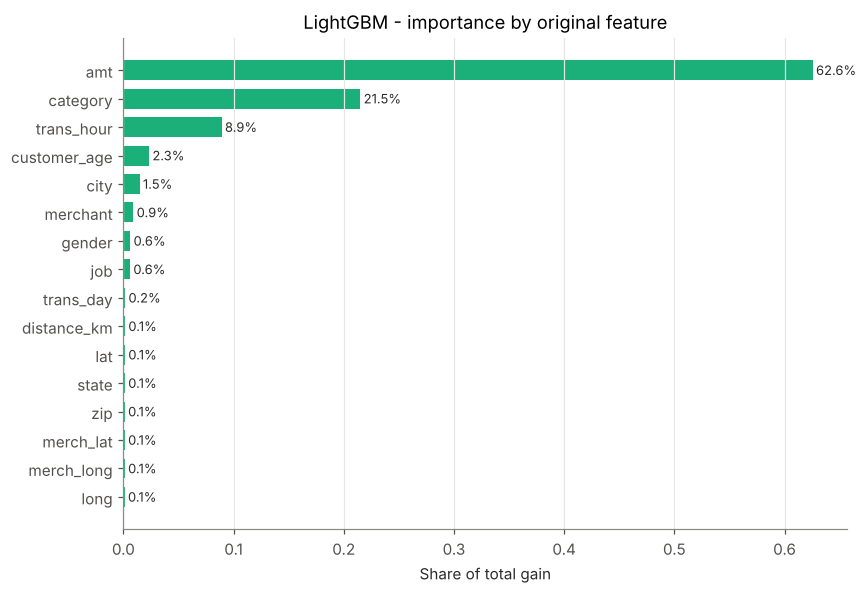

In [48]:
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(importance.index, importance.values, color=MODEL_COLORS[best_model_name], height=0.7)
for i, v in enumerate(importance.values):
    ax.text(v + 0.003, i, f"{v:.1%}", va="center", fontsize=8.5, color="#2b2b2a")
ax.set_xlabel(f"Share of total {importance_label}")
ax.set_title(f"{best_model_name} - importance by original feature")
ax.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

**Interpretation:** the model relies mainly on **`amt` (≈ 63 %)**, **`category` (≈ 22 %)** and the engineered **`trans_hour` (≈ 9 %)**, followed by `customer_age` (≈ 2 %). This agrees with the Task 1 EDA findings on amount and category, and shows that the Task 2 time feature adds value. Geographic coordinates and `distance_km` contribute very little. Importance shows what the model uses, not causation.

## 15 Saving, Reloading, and Inference

### 15.1 Save the Complete Pipeline

The **whole fitted pipeline** (Task 2 preprocessing + tuned LightGBM) is saved, because the learned medians, scaling statistics and categories are needed to transform new data in exactly the same way.

In [49]:
MODEL_PATH = f"{OUTPUT_DIR}/final_model_pipeline.joblib"
METADATA_PATH = f"{OUTPUT_DIR}/model_metadata.json"

joblib.dump(final_pipeline, MODEL_PATH, compress=3)
print(f"Saved {MODEL_PATH} ({os.path.getsize(MODEL_PATH) / 1024:,.1f} KB)")

Saved task3_output_improved/final_model_pipeline.joblib (1,184.4 KB)


### 15.2 Save the Model Metadata

Feature names, hyperparameters, decision threshold, CV and test metrics, library versions and the inference method are stored as JSON.

In [50]:
def to_builtin(value):
    """Convert numpy types so that the metadata can be written as JSON."""
    if isinstance(value, (np.integer,)):
        return int(value)
    if isinstance(value, (np.floating,)):
        return float(value)
    return value


best_cv = tuned_results[best_model_name]["folds"]
metadata = {
    "project": "Credit Card Fraud Detection - Task 3",
    "model_name": best_model_name,
    "model_class": type(final_pipeline.named_steps["model"]).__name__,
    "target": TARGET,
    "positive_class": "1 = fraud",
    "input_features": X_train.columns.tolist(),
    "numerical_features": numerical_features,
    "categorical_features": categorical_features,
    "n_processed_features": int(n_processed),
    "dropped_raw_columns": DROP_COLUMNS,
    "engineered_features": ["trans_hour", "trans_day", "customer_age", "distance_km"],
    "hyperparameters": {k: to_builtin(v) for k, v in tuned_settings[best_model_name].items()},
    "decision_threshold": DECISION_THRESHOLD,
    "selection_metric": "average_precision (5-fold StratifiedKFold CV on 250,000-row training subsample)",
    "cv_metrics_mean": {k: float(best_cv[f"val_{k}"].mean()) for k in test_metrics},
    "cv_metrics_std": {k: float(best_cv[f"val_{k}"].std()) for k in test_metrics},
    "test_metrics": {k: float(v) for k, v in test_metrics.items()},
    "train_rows_final_fit": int(X_train.shape[0]),
    "final_fit_time_s": round(final_fit_time, 2),
    "library_versions": {"python": platform.python_version(), "pandas": pd.__version__,
                         "scikit-learn": sklearn.__version__, "lightgbm": lightgbm.__version__,
                         "joblib": joblib.__version__},
    "inference": ("raw transaction rows -> prepare_features() (Task 2 create_features + drop columns) "
                  "-> pipeline.predict_proba(X)[:, 1] -> fraud if probability >= decision_threshold"),
}
with open(METADATA_PATH, "w") as f:
    json.dump(metadata, f, indent=2)

print(f"Saved {METADATA_PATH} ({os.path.getsize(METADATA_PATH) / 1024:,.1f} KB)")

Saved task3_output_improved/model_metadata.json (2.5 KB)


### 15.3 Reload the Saved Artifacts

The pipeline and metadata are loaded **from disk** into new variables, independent of the in-memory objects.

In [51]:
loaded_pipeline = joblib.load(MODEL_PATH)
with open(METADATA_PATH) as f:
    loaded_metadata = json.load(f)
threshold = loaded_metadata["decision_threshold"]

print("Loaded model    :", loaded_metadata["model_name"], "-", type(loaded_pipeline).__name__,
      [step for step, _ in loaded_pipeline.steps])
print("Input features  :", len(loaded_metadata["input_features"]))
print("Threshold       :", round(threshold, 4))

Loaded model    : LightGBM - Pipeline ['preprocessor', 'model']
Input features  : 17
Threshold       : 0.7397


### 15.4 Inference on Sample Raw Transactions

**Inference method:**

1. Start from raw transaction rows with the original raw columns.

The demonstration uses raw rows from the **training** file, so the test set stays reserved for the single evaluation in Section 13.
2. Apply `prepare_features()` (Task 2 feature engineering and column removal).
3. Call `pipeline.predict_proba(X)[:, 1]`; the pipeline applies imputation, scaling and one-hot encoding itself.
4. Flag the transaction as fraud if the probability is ≥ the saved `decision_threshold`.

In [52]:
# Sample input: 5 legitimate + 5 fraudulent RAW training transactions (test set stays untouched)
sample_raw = pd.concat([
    df_train[df_train[TARGET] == 0].sample(5, random_state=RANDOM_STATE),
    df_train[df_train[TARGET] == 1].sample(5, random_state=RANDOM_STATE),
])

sample_X = prepare_features(sample_raw).drop(columns=[TARGET])[loaded_metadata["input_features"]]
sample_proba = loaded_pipeline.predict_proba(sample_X)[:, 1]

sample_output = sample_raw[["trans_date_trans_time", "category", "amt", TARGET]].copy()
sample_output["fraud_probability"] = sample_proba.round(4)
sample_output["predicted_label"] = (sample_proba >= threshold).astype(int)
display(sample_output.reset_index(drop=True))

,trans_date_trans_time,category,amt,is_fraud,fraud_probability,predicted_label
0,2019-12-07 10:55:06,gas_transport,86.19,0,0.0001,0
1,2020-04-03 13:10:06,entertainment,85.81,0,0.0002,0
2,2019-12-04 07:07:04,grocery_pos,99.30,0,0.0000,0
3,2019-06-30 18:43:08,home,42.09,0,0.0000,0
4,2019-04-15 19:57:49,shopping_net,4.24,0,0.0000,0
5,2019-11-20 22:18:56,grocery_pos,312.51,1,0.9962,1
6,2020-02-02 23:13:33,kids_pets,20.53,1,0.7052,0
7,2019-12-04 01:53:21,grocery_pos,264.10,1,0.9850,1
8,2019-03-04 22:11:30,shopping_net,987.73,1,0.9969,1
9,2019-12-11 22:37:25,shopping_net,868.00,1,0.9849,1


**Interpretation:** all five legitimate training transactions receive probabilities close to 0 and are classified correctly. Four of the five frauds are detected with probabilities above 0.98. The missed fraud (`kids_pets`, amount 20.53) has a probability of 0.7052: above 0.5 but just below the selected threshold of 0.7397. This shows the precision–recall trade-off of the higher threshold: fewer false alarms, but some borderline frauds are missed.

### 15.5 Verify the Reloaded Pipeline

The reloaded pipeline must reproduce the in-memory predictions exactly. The check uses 2,000 rows from the **training** data, so the test set is not touched again.

In [53]:
check_rows = X_train.sample(2_000, random_state=RANDOM_STATE)
identical = np.allclose(loaded_pipeline.predict_proba(check_rows)[:, 1],
                        final_pipeline.predict_proba(check_rows)[:, 1])
print("Reloaded pipeline reproduces the original predictions:", identical)

Reloaded pipeline reproduces the original predictions: True


## 16 Conclusion and Submission Checklist

### 16.1 Conclusion

| Stage | Outcome |
|---|---|
| Problem | Binary classification of credit-card fraud with severe imbalance (≈ 0.58 % fraud); main metric: Average Precision |
| Models | Logistic Regression, Random Forest and LightGBM, all with the same Task 2 preprocessing inside leakage-safe pipelines |
| Validation | Stratified 5-fold CV on a 250,000-row stratified training sample; same folds for every baseline and search |
| Default baselines (val AP) | LR 0.224 · RF 0.792 · LightGBM 0.648 ± 0.196 (unstable) |
| Tuning (val AP) | LR 0.238 · RF 0.809 · **LightGBM 0.888 ± 0.014** |
| Selected model | Tuned LightGBM, chosen from CV evidence only; decision threshold ≈ 0.74 from out-of-fold predictions |
| Final test (once) | AP ≈ 0.844, ROC-AUC ≈ 0.996, precision ≈ 0.84, recall ≈ 0.76, F1 ≈ 0.80 |
| Delivery | Complete pipeline and metadata saved, reloaded and verified |

### 16.2 Submission Checklist

- [x] Runnable notebook with research summary and three documented model pipelines (Sections 04–05).
- [x] Default baselines, validation / CV output, tuning experiments, and suitable metrics / plots (Sections 06–10).
- [x] One comparison table with a justified best-model choice and final results (Sections 11–13).
- [x] Saved model / pipeline, required metadata, and a successful reload demonstration (Section 15).